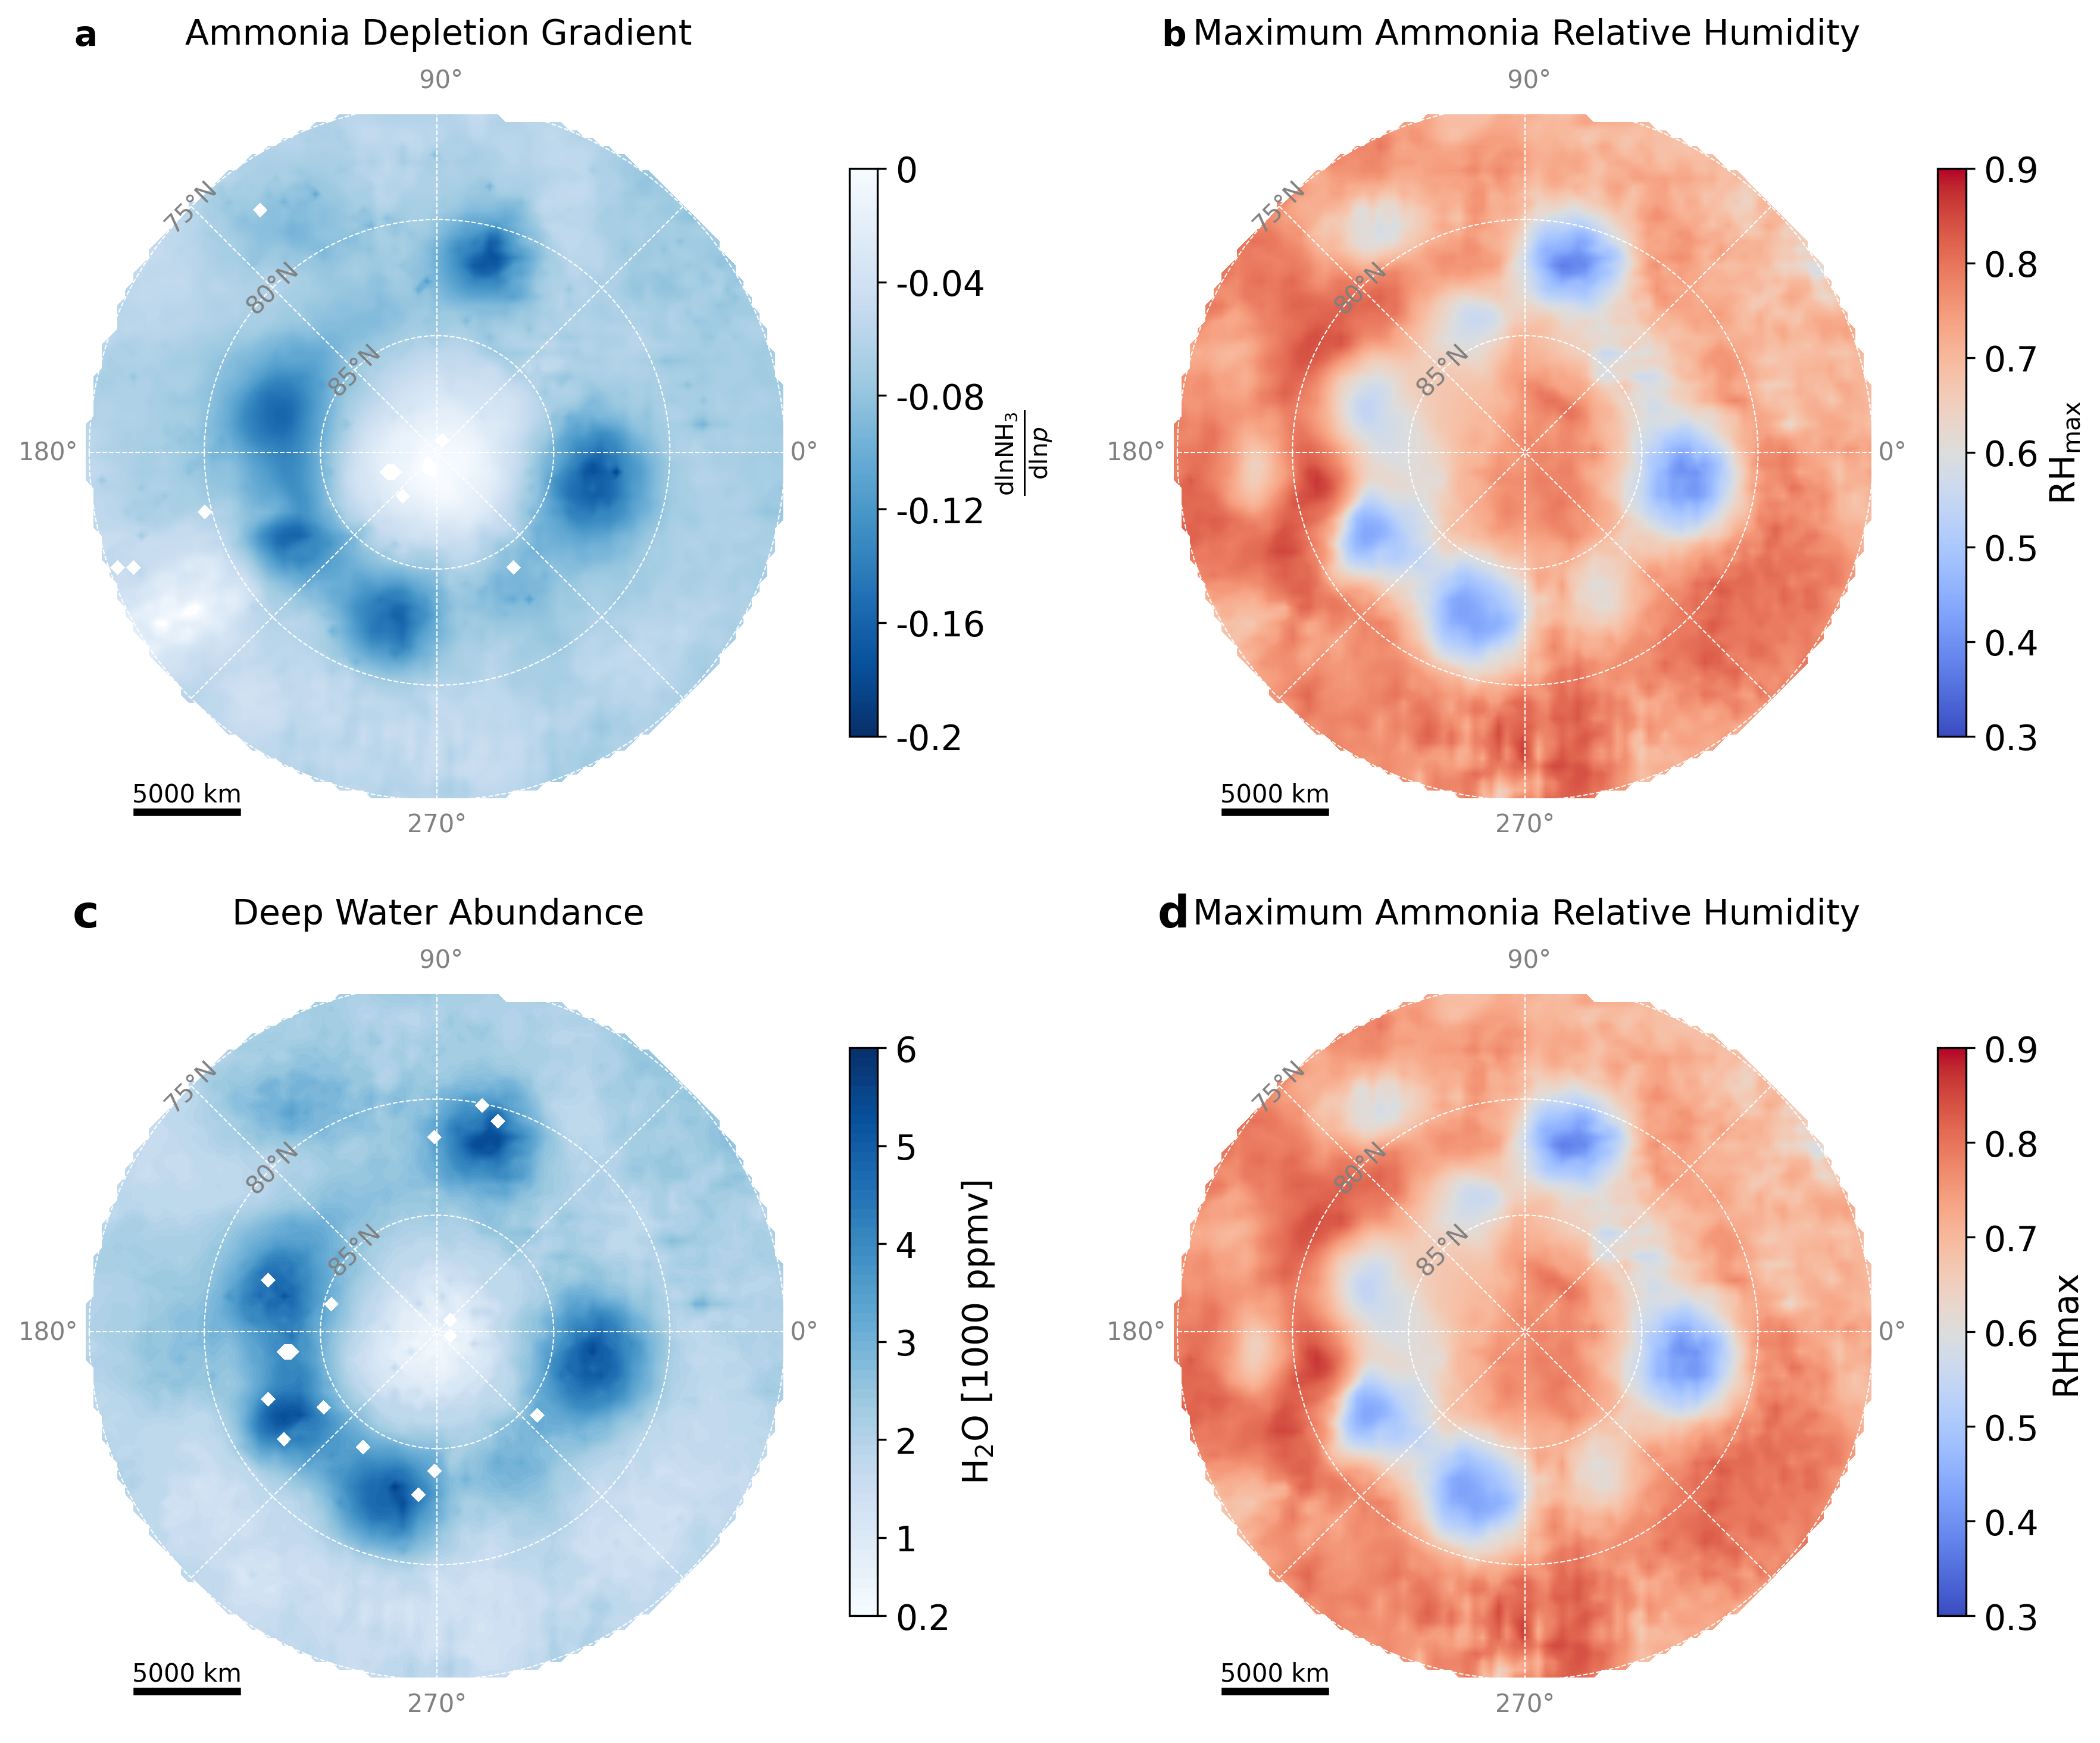

In [1]:
## plot the thetas_in_grid (:,:,0) and (:,:,1) to see the distribution of RHmax and adlnNH3dlnP
import matplotlib.pyplot as plt
import h5py
import numpy as np
import matplotlib.pyplot as plt

def plot_polar_grids(ax):
    def trans_coordiantes(lat, lon):
        # Jupiter's radii in km
        R_equator = 71492.0  # Equatorial radius
        R_polar = 66854.0    # Polar radius

        # Convert lat and lon to radians
        lat_rad = np.radians(lat)
        lon_rad = np.radians(lon)

        # Calculate the radius for each latitude (ellipsoidal shape of Jupiter)
        R = R_equator * np.cos(lat_rad)**2 + R_polar * np.sin(lat_rad)**2

        # Compute Cartesian coordinates
        x = R * np.cos(lat_rad) * np.cos(lon_rad)
        y = R * np.cos(lat_rad) * np.sin(lon_rad)

        return x, y

    for ll in [85,80,75]:
        lons=np.linspace(-180, 180, 100)
        lats=np.linspace(ll, ll, 100)
        xg,yg=trans_coordiantes(lats, lons)
        color='white'
        # if ll==75: lw=1 ; linestyle="-"; color='k'
        # else: 
        lw=0.5; linestyle="--"
        ax.plot(xg,yg,linestyle=linestyle, color=color, lw=lw)
        
        x,y=trans_coordiantes(ll, 135)
        ax.text(x,y, f"{ll:2.0f}°N", color='gray', va='center', ha="center", rotation=45)


    for oo in np.linspace(0,315,8):
        lons=np.linspace(oo, oo, 100)
        lats=np.linspace(75, 90, 100)
        xg,yg=trans_coordiantes(lats, lons)
        ax.plot(xg,yg,"--", color='white', lw=0.5)
        if oo%90==0:
            x,y=trans_coordiantes(74.5, oo)
            ha="center"
            va='center'
            if oo==180 : ha="right"
            if oo==270 : va="top"
            if oo==90 : va="bottom"
            ax.text(x,y, f"{oo:3.0f}°", color='gray',  va=va, ha=ha)

    # Add a scalebar for 5000 km and 10,000 km
    scalebar_x = x.min()-15000   # Adjust position (X-coordinate)
    scalebar_y = y.min()  # Adjust position (Y-coordinate)
    scalebar_width = 3000  # Adjust the thickness of the scale bar

    # Scale bar for 5000 km
    ax.plot([scalebar_x, scalebar_x + 5000], [scalebar_y, scalebar_y], 
            color='black', lw=3, label='5000 km')
    ax.text(scalebar_x + 2500, scalebar_y + scalebar_width/2, '5000 km', 
            ha='center', va='top')

    for spine in ax.spines.values():
        spine.set_visible(False)

    ax.set_xticks([])
    ax.set_yticks([])


with h5py.File("../thetas_in_grid_pseudo.h5", "r") as f:
# with h5py.File("thetas_in_grid.h5", "r") as f:
    thetas = f["thetas"][:]
 
## read from file the x_cor and y_cor
with h5py.File("../observation/tb_anomaly_grided_PJ51_PJ61_FA02.h5", "r") as h5f:
    x_cor = h5f["x"][0,:]
    y_cor = h5f["y"][:,0]
    

with h5py.File("../profile_in_grid_pseudo.h5", "r") as f:
    chi = f["chi"][:]

mask=chi>4
thetas[mask,:] = np.nan

H2O = thetas[:, :, 0]
rhmax = thetas[:, :, 1]
# pmax=thetas[:, :, 2]



# rhmax = np.transpose(rhmax, (1, 0))
# adln = np.transpose(adln, (1, 0))

## set rhmax=0 as nan
H2O[H2O==0] = np.nan
rhmax[rhmax==0] = np.nan
## set adln<-0.23 as nan
# adln[adln<=-0.2] =-0.1
# adln[adln == 0] = np.nan


## plot the thetas_in_grid (:,:,0) and (:,:,1) to see the distribution of RHmax and adlnNH3dlnP
import matplotlib.pyplot as plt
import h5py
import numpy as np
import matplotlib.pyplot as plt



with h5py.File("../thetas_in_grid_dry.h5", "r") as f:
# with h5py.File("thetas_in_grid_correct.h5", "r") as f:
    thetas = f["thetas"][:]
 
# print(y_cor)
# print(x_cor)
with h5py.File("../profiles_in_grid_dry.h5", "r") as f:
    chi = f["chi"][:]


rhmax = thetas[:, :, 0]
adln = thetas[:, :, 1]
pmax=thetas[:, :, 2]



# rhmax = np.transpose(rhmax, (1, 0))
# adln = np.transpose(adln, (1, 0))

## set rhmax=0 as nan
rhmax[rhmax==0] = np.nan
## set adln<-0.23 as nan
# adln[adln<=-0.2] =-0.1
adln[adln == 0] = np.nan

adln[pmax<3.5] = np.nan
pmax[pmax==0] = np.nan






fig, [[ax, ax0], [ax1, ax2]] = plt.subplots(2,2, figsize=(12, 10), dpi=300)


c = ax.contourf(x_cor, y_cor, adln, levels=np.linspace(-0.2, 0, 255), cmap='Blues_r')
# color bar
cbar = plt.colorbar(c, ax=ax, orientation='vertical', shrink=0.7, pad=0.02)
cbar.set_label(r'$\frac{\text{dlnNH}_3}{\text{dln}p}$', fontsize=14)
cbar.ax.set_yticks([-0.2,-0.16,-0.12,-0.08,-0.04,0])
cbar.ax.set_yticklabels([-0.2,-0.16,-0.12,-0.08,-0.04,0], fontsize=14)
plot_polar_grids(ax)
ax.set_title("Ammonia Depletion Gradient", fontsize=14)
ax.set_aspect('equal')


c = ax0.contourf(x_cor, y_cor, rhmax, levels=np.linspace(0.3, 0.9, 255), cmap='coolwarm')
cbar = plt.colorbar(c, ax=ax0, orientation='vertical', shrink=0.7, pad=0.02)
cbar.ax.set_yticks([0.3,0.4,0.5,0.6,0.7,0.8,0.9])
cbar.ax.set_yticklabels([0.3,0.4,0.5,0.6,0.7,0.8,0.9], fontsize=14)
cbar.set_label(r"RH$_\text{max}$", fontsize=14)
plot_polar_grids(ax0)
ax0.set_title("Maximum Ammonia Relative Humidity", fontsize=14)
ax0.set_aspect('equal')





ax.text(0.05, 1.03, f'a', ha='center', va='center', fontweight='bold',fontsize=14, transform=ax.transAxes)
ax0.text(0.05, 1.03, f'b', ha='center', va='center', fontweight='bold',fontsize=14, transform=ax0.transAxes)

c = ax1.contourf(x_cor, y_cor, H2O, levels= np.linspace(0.2, 6, 61), cmap='Blues')
cbar = plt.colorbar(c, ax=ax1, orientation='vertical', shrink=0.7, pad=0.02)
cbar.ax.set_yticks([0.2,1,2,3,4,5,6])
cbar.ax.set_yticklabels([0.2,1,2,3,4,5,6], fontsize=14)
cbar.set_label(r"H$_2$O [1000 ppmv]", fontsize=14)
plot_polar_grids(ax1)
ax1.set_title("Deep Water Abundance", fontsize=14)
ax1.set_aspect('equal')


c = ax2.contourf(x_cor, y_cor, rhmax, levels=np.linspace(0.3, 0.9, 255), cmap='coolwarm')
# color bar
cbar = plt.colorbar(c, ax=ax2, orientation='vertical', shrink=0.7, pad=0.02)
cbar.set_label('RHmax', fontsize=14)
cbar.ax.set_yticks([0.3,0.4,0.5,0.6,0.7,0.8,0.9])
cbar.ax.set_yticklabels([0.3,0.4,0.5,0.6,0.7,0.8,0.9], fontsize=14)
# cbar.ax.set_yticks([-0.16,-0.13,-0.1,-0.07,-0.04,-0.01])
# cbar.ax.set_yticklabels([-0.16,-0.13,-0.1,-0.07,-0.04,-0.01])

plot_polar_grids(ax2)
ax2.set_title("Maximum Ammonia Relative Humidity", fontsize=14)
ax2.set_aspect('equal')

ax1.text(0.05, 1.03, f'{chr(99)}', ha='center', va='center', fontweight='bold',fontsize=18, transform=ax1.transAxes)
ax2.text(0.05, 1.03, f'{chr(100)}', ha='center', va='center', fontweight='bold',fontsize=18, transform=ax2.transAxes)


plt.tight_layout()
plt.show()

Plotting at level 1 bar, index 919


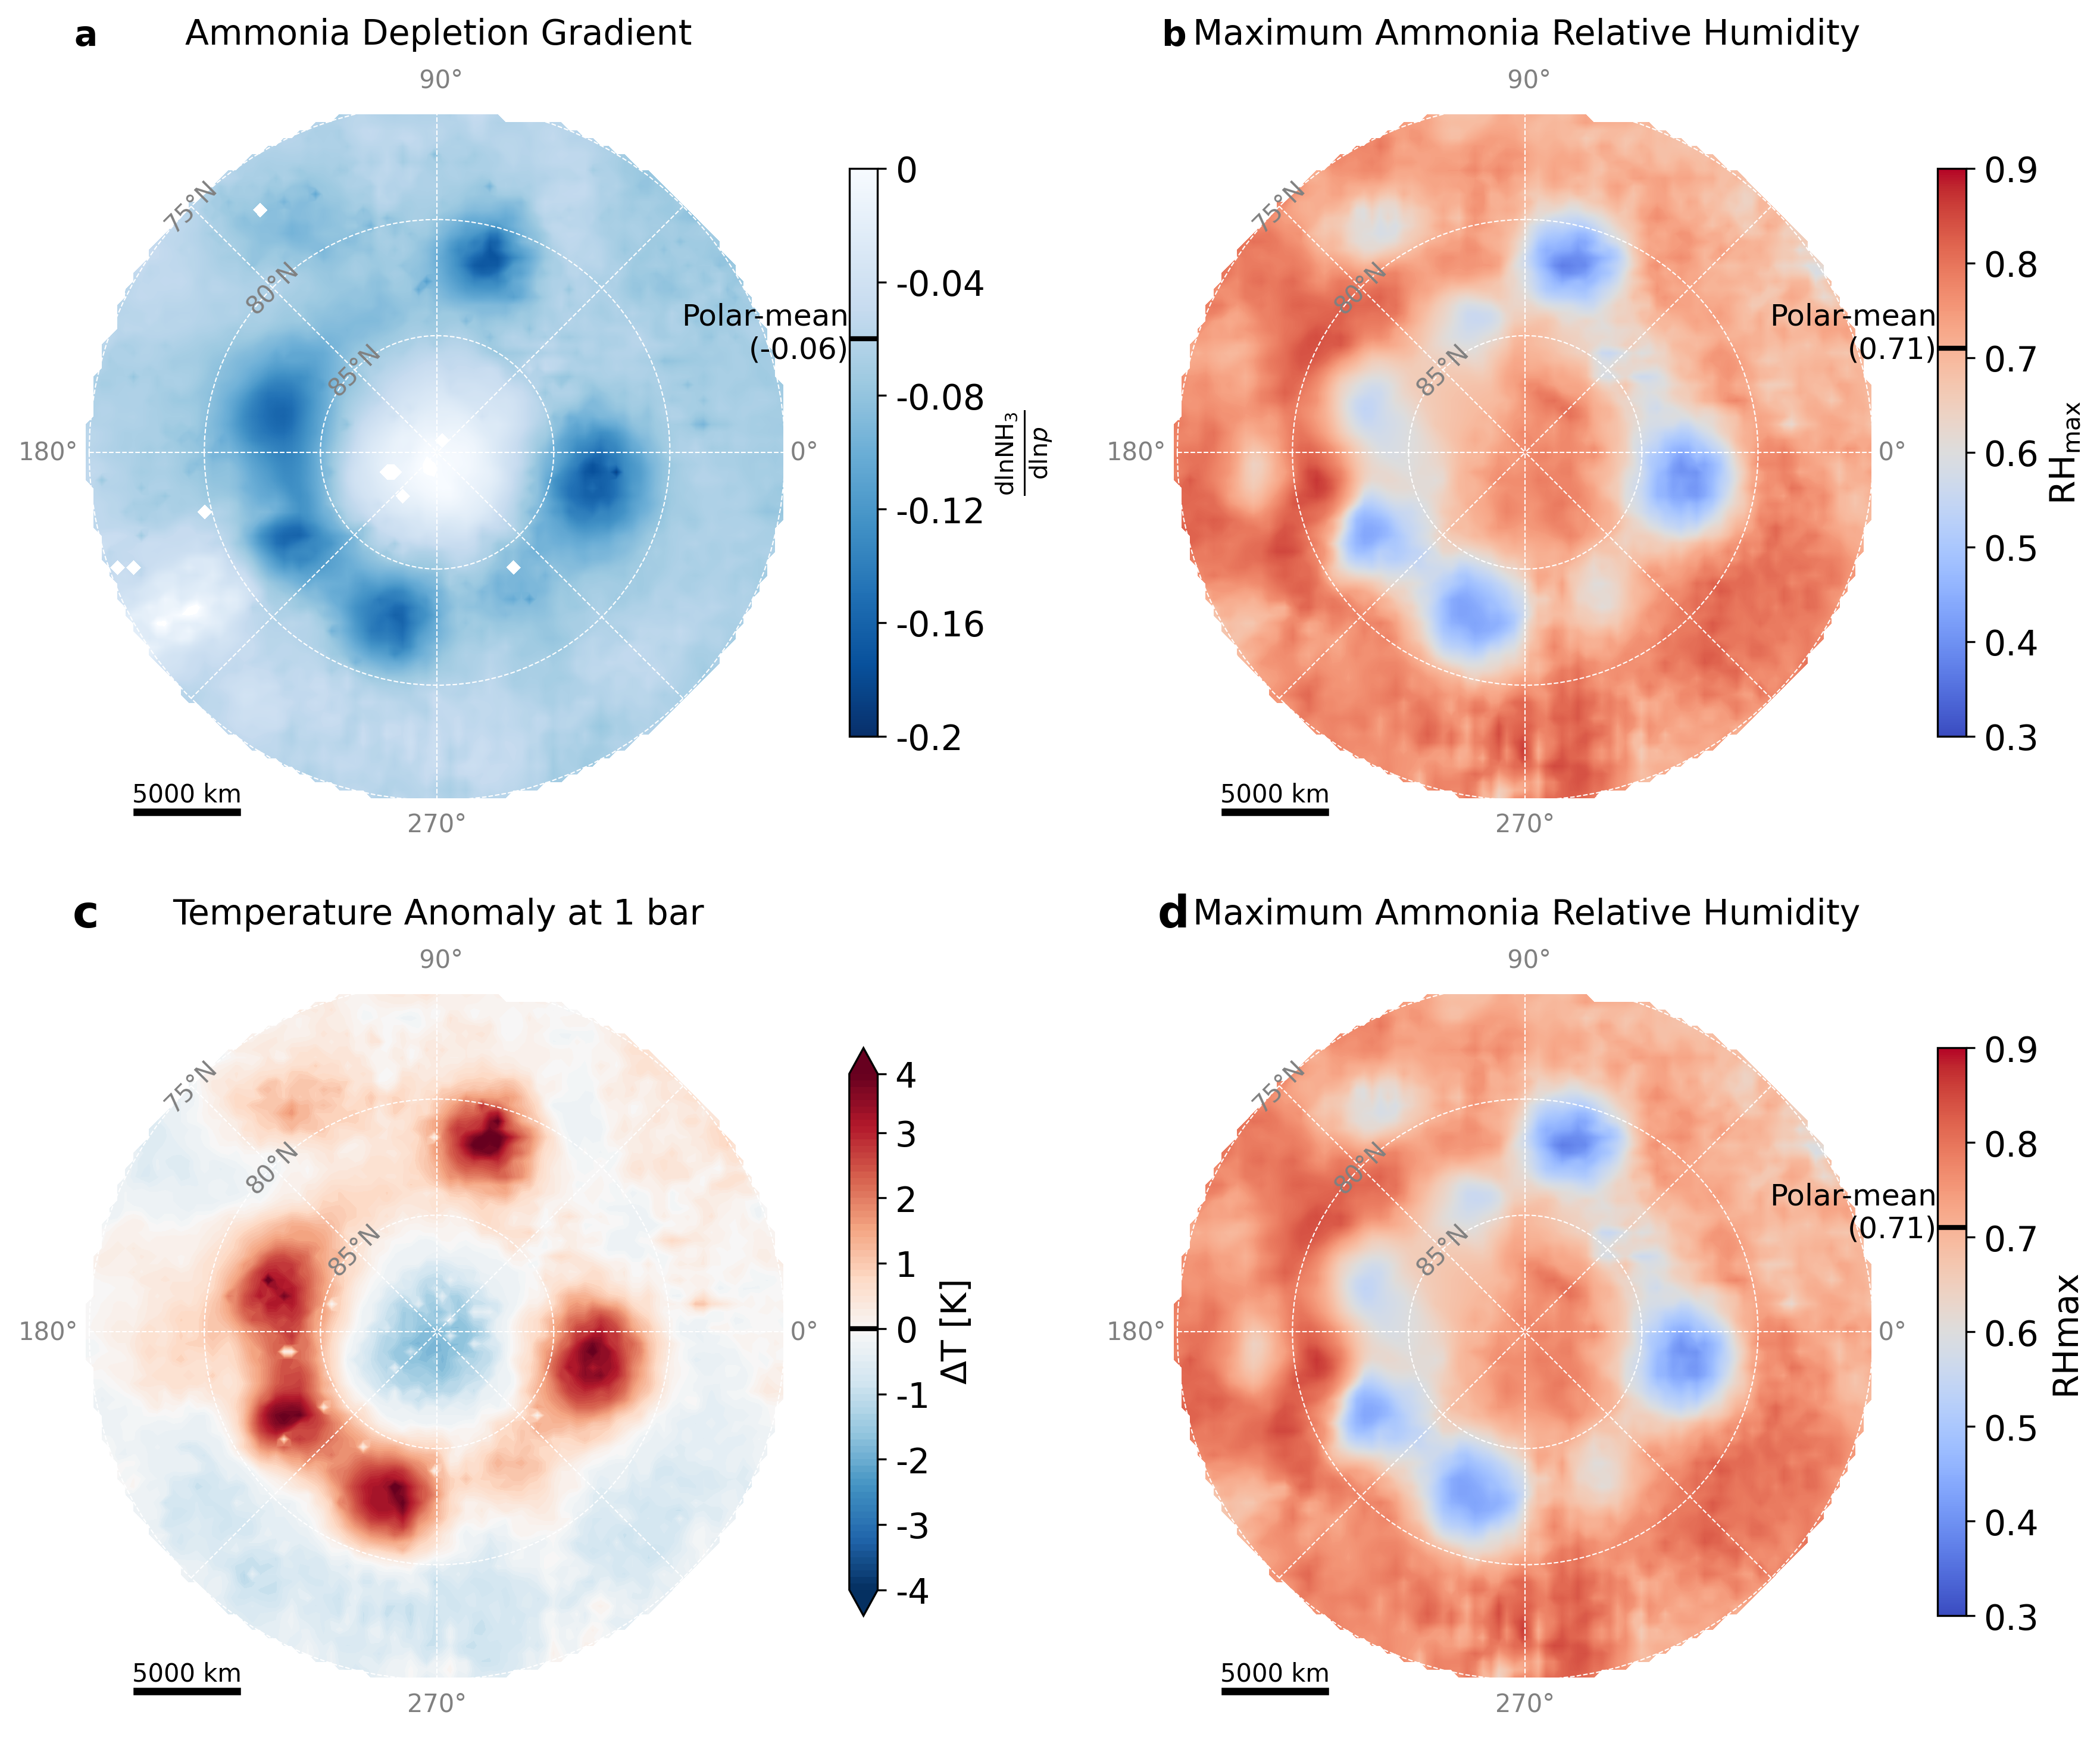

In [2]:
## plot the thetas_in_grid (:,:,0) and (:,:,1) to see the distribution of RHmax and adlnNH3dlnP
import matplotlib.pyplot as plt
import h5py
import numpy as np
import matplotlib.pyplot as plt

def plot_polar_grids(ax):
    def trans_coordiantes(lat, lon):
        # Jupiter's radii in km
        R_equator = 71492.0  # Equatorial radius
        R_polar = 66854.0    # Polar radius

        # Convert lat and lon to radians
        lat_rad = np.radians(lat)
        lon_rad = np.radians(lon)

        # Calculate the radius for each latitude (ellipsoidal shape of Jupiter)
        R = R_equator * np.cos(lat_rad)**2 + R_polar * np.sin(lat_rad)**2

        # Compute Cartesian coordinates
        x = R * np.cos(lat_rad) * np.cos(lon_rad)
        y = R * np.cos(lat_rad) * np.sin(lon_rad)

        return x, y

    for ll in [85,80,75]:
        lons=np.linspace(-180, 180, 100)
        lats=np.linspace(ll, ll, 100)
        xg,yg=trans_coordiantes(lats, lons)
        color='white'
        # if ll==75: lw=1 ; linestyle="-"; color='k'
        # else: 
        lw=0.5; linestyle="--"
        ax.plot(xg,yg,linestyle=linestyle, color=color, lw=lw)
        
        x,y=trans_coordiantes(ll, 135)
        ax.text(x,y, f"{ll:2.0f}°N", color='gray', va='center', ha="center", rotation=45)


    for oo in np.linspace(0,315,8):
        lons=np.linspace(oo, oo, 100)
        lats=np.linspace(75, 90, 100)
        xg,yg=trans_coordiantes(lats, lons)
        ax.plot(xg,yg,"--", color='white', lw=0.5)
        if oo%90==0:
            x,y=trans_coordiantes(74.5, oo)
            ha="center"
            va='center'
            if oo==180 : ha="right"
            if oo==270 : va="top"
            if oo==90 : va="bottom"
            ax.text(x,y, f"{oo:3.0f}°", color='gray',  va=va, ha=ha)

    # Add a scalebar for 5000 km and 10,000 km
    scalebar_x = x.min()-15000   # Adjust position (X-coordinate)
    scalebar_y = y.min()  # Adjust position (Y-coordinate)
    scalebar_width = 3000  # Adjust the thickness of the scale bar

    # Scale bar for 5000 km
    ax.plot([scalebar_x, scalebar_x + 5000], [scalebar_y, scalebar_y], 
            color='black', lw=3, label='5000 km')
    ax.text(scalebar_x + 2500, scalebar_y + scalebar_width/2, '5000 km', 
            ha='center', va='top')

    for spine in ax.spines.values():
        spine.set_visible(False)

    ax.set_xticks([])
    ax.set_yticks([])


with h5py.File("../thetas_in_grid_pseudo.h5", "r") as f:
# with h5py.File("thetas_in_grid.h5", "r") as f:
    thetas = f["thetas"][:]
 
## read from file the x_cor and y_cor
with h5py.File("../observation/tb_anomaly_grided_PJ51_PJ61_FA02.h5", "r") as h5f:
    x_cor = h5f["x"][0,:]
    y_cor = h5f["y"][:,0]
    

with h5py.File("../profile_in_grid_pseudo.h5", "r") as f:
    chi = f["chi"][:]

mask=chi>4
thetas[mask,:] = np.nan

H2O = thetas[:, :, 0]
rhmax = thetas[:, :, 1]
# pmax=thetas[:, :, 2]



# rhmax = np.transpose(rhmax, (1, 0))
# adln = np.transpose(adln, (1, 0))

## set rhmax=0 as nan
H2O[H2O==0] = np.nan
rhmax[rhmax==0] = np.nan
## set adln<-0.23 as nan
# adln[adln<=-0.2] =-0.1
# adln[adln == 0] = np.nan

profile=h5py.File("../profile_in_grid_pseudo.h5", "r")
# nh3ppm=profile["ppm_NH3"][:]
# shs_all=profile["shs_nh3"][:]
# rhs_all=profile["rhs_nh3"][:]
# ppm_h2o=profile["ppm_h2o"][:]
temp=profile["temp"][:]
# theta=profile["ptemp"][:]
profile.close() 

temp[temp<10]=np.nan

mainout=h5py.File("../cpc_dry/bin/juno_forward_mwr_polarmean-main.nc", "r")
pressure=mainout["press"][0,:,0,0]*1E-5  # in bar
mainout.close()
ilev=np.argmin(np.abs(pressure - 1))
print(f"Plotting at level {1} bar, index {ilev}")
ppm_slice=temp[:, :, ilev]

## plot the thetas_in_grid (:,:,0) and (:,:,1) to see the distribution of RHmax and adlnNH3dlnP
import matplotlib.pyplot as plt
import h5py
import numpy as np
import matplotlib.pyplot as plt



with h5py.File("../thetas_in_grid_dry.h5", "r") as f:
# with h5py.File("thetas_in_grid_correct.h5", "r") as f:
    thetas = f["thetas"][:]
 
# print(y_cor)
# print(x_cor)
with h5py.File("../profiles_in_grid_dry.h5", "r") as f:
    chi = f["chi"][:]


rhmax = thetas[:, :, 0]
adln = thetas[:, :, 1]
pmax=thetas[:, :, 2]



# rhmax = np.transpose(rhmax, (1, 0))
# adln = np.transpose(adln, (1, 0))

## set rhmax=0 as nan
rhmax[rhmax==0] = np.nan
## set adln<-0.23 as nan
# adln[adln<=-0.2] =-0.1
adln[adln == 0] = np.nan

adln[pmax<3.5] = np.nan
pmax[pmax==0] = np.nan






fig, [[ax, ax0], [ax1, ax2]] = plt.subplots(2,2, figsize=(12, 10), dpi=300)


c = ax.contourf(x_cor, y_cor, adln, levels=np.linspace(-0.2, 0, 255), cmap='Blues_r')
# color bar
cbar = plt.colorbar(c, ax=ax, orientation='vertical', shrink=0.7, pad=0.02)
cbar.set_label(r'$\frac{\text{dlnNH}_3}{\text{dln}p}$', fontsize=14)
cbar.ax.set_yticks([-0.2,-0.16,-0.12,-0.08,-0.04,0])
cbar.ax.set_yticklabels([-0.2,-0.16,-0.12,-0.08,-0.04,0], fontsize=14)
cbar.ax.axhline(-0.06, color='black', linestyle='-', linewidth=2)
cbar.ax.text(-0.02, 0.71, 'Polar-mean\n(-0.06)', ha='right', va='center',fontsize=12, transform=cbar.ax.transAxes)

plot_polar_grids(ax)
ax.set_title("Ammonia Depletion Gradient", fontsize=14)
ax.set_aspect('equal')


c = ax0.contourf(x_cor, y_cor, rhmax, levels=np.linspace(0.3, 0.9, 255), cmap='coolwarm')
cbar = plt.colorbar(c, ax=ax0, orientation='vertical', shrink=0.7, pad=0.02)
cbar.ax.set_yticks([0.3,0.4,0.5,0.6,0.7,0.8,0.9])
cbar.ax.set_yticklabels([0.3,0.4,0.5,0.6,0.7,0.8,0.9], fontsize=14)
cbar.set_label(r"RH$_\text{max}$", fontsize=14)
cbar.ax.axhline(0.71, color='black', linestyle='-', linewidth=2)
cbar.ax.text(-0.02, 0.71, 'Polar-mean\n(0.71)', ha='right', va='center',fontsize=12, transform=cbar.ax.transAxes)

plot_polar_grids(ax0)
ax0.set_title("Maximum Ammonia Relative Humidity", fontsize=14)
ax0.set_aspect('equal')





ax.text(0.05, 1.03, f'a', ha='center', va='center', fontweight='bold',fontsize=14, transform=ax.transAxes)
ax0.text(0.05, 1.03, f'b', ha='center', va='center', fontweight='bold',fontsize=14, transform=ax0.transAxes)

c = ax1.contourf(x_cor, y_cor, ppm_slice-178, levels= np.arange(174, 182, 0.1)-178, cmap='RdBu_r', extend='both')
cbar = plt.colorbar(c, ax=ax1, orientation='vertical', shrink=0.7, pad=0.02)
cbar.ax.axhline(0, color='black', linestyle='-', linewidth=2)
# cbar.ax.text(-0.02, 0.25, r'Polar-mean T$_\mathrm{1bar}$\n(177.9 K)', color='r', ha='right', va='center', fontsize=12, transform=cbar.ax.transAxes)

cbar.ax.set_yticks([-4, -3, -2, -1, 0, 1, 2, 3, 4])
cbar.ax.set_yticklabels([-4, -3, -2, -1, 0, 1, 2, 3, 4], fontsize=14)
cbar.set_label(r"$\Delta$T [K]", fontsize=14)
plot_polar_grids(ax1)
ax1.set_title("Temperature Anomaly at 1 bar", fontsize=14)
ax1.set_aspect('equal')


c = ax2.contourf(x_cor, y_cor, rhmax, levels=np.linspace(0.3, 0.9, 255), cmap='coolwarm')
# color bar
cbar = plt.colorbar(c, ax=ax2, orientation='vertical', shrink=0.7, pad=0.02)
cbar.set_label('RHmax', fontsize=14)
cbar.ax.set_yticks([0.3,0.4,0.5,0.6,0.7,0.8,0.9])
cbar.ax.set_yticklabels([0.3,0.4,0.5,0.6,0.7,0.8,0.9], fontsize=14)
# cbar.ax.set_yticks([-0.16,-0.13,-0.1,-0.07,-0.04,-0.01])
# cbar.ax.set_yticklabels([-0.16,-0.13,-0.1,-0.07,-0.04,-0.01])
cbar.ax.axhline(0.71, color='black', linestyle='-', linewidth=2)
cbar.ax.text(-0.02, 0.71, 'Polar-mean\n(0.71)', ha='right', va='center',fontsize=12, transform=cbar.ax.transAxes)

plot_polar_grids(ax2)
ax2.set_title("Maximum Ammonia Relative Humidity", fontsize=14)
ax2.set_aspect('equal')

ax1.text(0.05, 1.03, f'{chr(99)}', ha='center', va='center', fontweight='bold',fontsize=18, transform=ax1.transAxes)
ax2.text(0.05, 1.03, f'{chr(100)}', ha='center', va='center', fontweight='bold',fontsize=18, transform=ax2.transAxes)


plt.tight_layout()
plt.show()